# AQHDA — Five-Seed Baseline Experiment

Three public datasets, **natural class ratios**, 60/20/20 stratified split per seed. Methods: no augmentation, SMOTENC, CTGAN and TVAE. Each seed reruns generators and XGBoost. Validation determines the classification threshold; test sets are not used for tuning.

**Outputs:** per-run CSVs; mean ± sample SD for class-specific precision, recall, F1, AUROC and AP; synthetic quality and label consistency; mean ROC graphs. No generated result numbers are assumed.

**Important:** The first part of this notebook is the five-seed baseline experiment; the second part is a preliminary AQHDA/Optuna extension (validation-only selection, then a single held-out test evaluation at the end). GAN and VAE training five times on three datasets can take substantial compute time; start with `EPOCHS = 30` for a preliminary demonstration. In scientific reporting, describe the epoch count as a limitation.

Undefined correlations (e.g., constant numeric columns) are excluded from dependency gaps. If no comparable pairs exist, the result is explicitly shown as **N/A (undefined)** rather than zero.

**Telco preprocessing note:** `TotalCharges` is stored as text in the source CSV; `load_dataset` now converts it to numeric (blank values are imputed with the training median after the split). Any Telco results or saved `aqhda_selected_*telco*.csv` files produced before this change used the old categorical treatment and must be regenerated by rerunning all cells. Run all cells in order; the AQHDA test cell needs the saved `aqhda_selected_*.csv` files from the Optuna cell.


## Install dependencies

In [1]:
%pip -q install ucimlrepo imbalanced-learn ctgan xgboost

## Imports and settings

In [2]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score,
                             precision_score, recall_score, roc_curve, precision_recall_curve, auc)
import matplotlib.pyplot as plt
from IPython.display import display
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTENC
from ctgan import CTGAN, TVAE

SEED = 42
EPOCHS = 30  # Fast demonstration, NOT a tuned or publication-quality generator
DATASETS = {"Bank Marketing": 222, "Online Shoppers": 468, "IBM Telco Churn": "telco"}
np.random.seed(SEED)


## Data loading and stratified splitting

In [3]:
def load_dataset(name, dataset_id):
    if dataset_id == "telco":
        # Public mirror of IBM Telco Churn data. customerID is an identifier, not a predictor.
        url = "https://raw.githubusercontent.com/Giskard-AI/examples/main/datasets/WA_Fn-UseC_-Telco-Customer-Churn.csv"
        df = pd.read_csv(url)
        y = df["Churn"].astype(str).str.strip().str.lower().eq("yes").astype(int)
        X = df.drop(columns=["Churn", "customerID"], errors="ignore").copy()
        # TotalCharges is stored as text (blank for new customers); convert to numeric BEFORE
        # feature typing so it is not treated as a categorical column.
        X["TotalCharges"] = pd.to_numeric(X["TotalCharges"].astype(str).str.strip(), errors="coerce")
        # SeniorCitizen is coded 0/1 but represents a category, not a continuous quantity.
        categories = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
        categories = list(dict.fromkeys(categories + ["SeniorCitizen"]))
        for col in categories:
            X[col] = X[col].astype("object")  # preserve missing values until after split
        numbers = [c for c in X.columns if c not in categories]
        X[numbers] = X[numbers].apply(pd.to_numeric, errors="coerce")
        print("Telco source rows:", len(X), "| blank TotalCharges (imputed with train median):",
              X["TotalCharges"].isna().sum())
        return X, y, categories, numbers
    data = fetch_ucirepo(id=dataset_id)
    X = data.data.features.copy()
    target = data.data.targets.iloc[:, 0].astype(str).str.strip().str.lower()
    y = target.isin(["yes", "true", "1"]).astype(int)
    if name == "Bank Marketing":
        X = X.drop(columns=["duration"], errors="ignore")  # Not available before the call
        categories = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    else:
        categories = ["Month", "OperatingSystems", "Browser", "Region",
                      "TrafficType", "VisitorType", "Weekend"]
    for col in categories:
        X[col] = X[col].astype("object")
    numbers = [c for c in X.columns if c not in categories]
    X[numbers] = X[numbers].apply(pd.to_numeric, errors="coerce")
    return X, y, categories, numbers

def split_and_fill(X, y, categories, numbers):
    X_train, X_tmp, y_train, y_tmp = train_test_split(
        X, y, test_size=0.40, stratify=y, random_state=SEED)
    X_val, X_test, y_val, y_test = train_test_split(
        X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
    # Missing-value statistics are computed only on the original training partition.
    X_train, X_val, X_test = X_train.copy(), X_val.copy(), X_test.copy()
    medians = X_train[numbers].median().fillna(0)
    for frame in (X_train, X_val, X_test):
        for c in numbers:
            frame[c] = pd.to_numeric(frame[c], errors="coerce").fillna(medians[c]).astype(float)
        for c in categories:
            frame[c] = frame[c].fillna("Missing").astype(str)
    # No augmentation or learned preprocessing is performed before this split.
    assert len(X_train) + len(X_val) + len(X_test) == len(X)
    assert set(X_train.index).isdisjoint(X_val.index)
    assert set(X_train.index).isdisjoint(X_test.index)
    assert set(X_val.index).isdisjoint(X_test.index)
    return X_train.copy(), X_val.copy(), X_test.copy(), y_train.copy(), y_val.copy(), y_test.copy()


## Synthetic sample generation

In [4]:
def generate_samples(method, X_train, y_train, categories, n_new):
    minority_features = X_train.loc[y_train == 1].copy()
    if method == "SMOTENC":
        sampler = SMOTENC(
            categorical_features=categories,
            sampling_strategy={1: int((y_train == 1).sum() + n_new)},
            random_state=SEED, k_neighbors=5)
        X_resampled, _ = sampler.fit_resample(X_train, y_train)
        synthetic = X_resampled.iloc[len(X_train):].copy()
    else:
        model = CTGAN(epochs=EPOCHS, verbose=False, enable_gpu=False) if method == "CTGAN" \
            else TVAE(epochs=EPOCHS, verbose=False, enable_gpu=False)
        # CTGAN/TVAE accept pandas object-based discrete columns reliably.
        generator_input = minority_features.copy()
        for col in categories:
            generator_input[col] = generator_input[col].astype("object")
        model.fit(generator_input, discrete_columns=categories)
        synthetic = model.sample(n_new)
    # Preserve original feature order without silently fixing invalid numbers/categories.
    synthetic = synthetic[X_train.columns].reset_index(drop=True)
    if len(synthetic) != n_new:
        raise ValueError(f"{method}: expected {n_new} synthetic rows, got {len(synthetic)}")
    # Never silently repair invalid generated values; report them for evaluation.
    return synthetic

## Statistical quality diagnostics

In [5]:
# Small evaluation functions: each measures an interpretable quantity.
def cramers_v(a, b):
    tab = pd.crosstab(pd.Series(a).reset_index(drop=True), pd.Series(b).reset_index(drop=True))
    n = tab.to_numpy().sum()
    if n == 0 or min(tab.shape) < 2:
        return 0.0
    obs = tab.to_numpy(dtype=float)
    expected = np.outer(obs.sum(axis=1), obs.sum(axis=0)) / n
    chi2 = ((obs - expected)**2 / np.where(expected == 0, 1, expected)).sum()
    return float(np.sqrt(max(0, chi2 / (n * (min(tab.shape)-1)))))

def correlation_ratio(categories, values):
    vals = pd.to_numeric(pd.Series(values).reset_index(drop=True), errors="coerce")
    groups = pd.Series(categories).reset_index(drop=True)
    valid = vals.notna()
    vals, groups = vals[valid], groups[valid]
    if len(vals) < 2 or vals.var() == 0:
        return 0.0
    grand_mean = vals.mean()
    between = sum(len(v) * (v.mean() - grand_mean)**2 for _, v in vals.groupby(groups))
    total = ((vals - grand_mean)**2).sum()
    return float(np.sqrt(max(0, between / total))) if total > 0 else 0.0

def dependency_scores(df, categories, numbers):
    # Compute associations on one dataset, then compare real against synthetic.
    result = {}
    for i, a in enumerate(numbers):
        for b in numbers[i+1:]:
            # Undefined for a constant column; exclude it from dependency comparisons.
            r = df[a].corr(df[b])
            result[("numeric", a, b)] = float(r) if pd.notna(r) else np.nan
    for i, a in enumerate(categories):
        for b in categories[i+1:]:
            result[("categorical", a, b)] = cramers_v(df[a], df[b])
    for a in categories:
        for b in numbers:
            result[("mixed", a, b)] = correlation_ratio(df[a], df[b])
    return result

def quality_scores(real_minority, synthetic, categories, numbers):
    real, syn = real_minority.reset_index(drop=True), synthetic.reset_index(drop=True)
    # Convert numeric columns without repairing invalid generated values.
    real = real.copy()
    syn = syn.copy()
    for c in numbers:
        real[c] = pd.to_numeric(real[c], errors="coerce")
        syn[c] = pd.to_numeric(syn[c], errors="coerce")
    invalid_cat = np.mean([(~syn[c].isin(real[c].dropna())).mean() for c in categories]) if categories else 0
    nonfinite = np.mean([(~np.isfinite(pd.to_numeric(syn[c], errors="coerce"))).mean() for c in numbers]) if numbers else 0
    range_gap = np.mean([((syn[c] < real[c].min()) | (syn[c] > real[c].max())).mean() for c in numbers]) if numbers else 0
    # Columns containing whole numbers in the original training data should remain whole numbers.
    int_cols = [c for c in numbers if np.allclose(real[c].dropna() % 1, 0)]
    integer_gap = np.mean([(np.abs(syn[c] - np.round(syn[c])) > 1e-6).mean() for c in int_cols]) if int_cols else 0
    real_assoc, syn_assoc = dependency_scores(real, categories, numbers), dependency_scores(syn, categories, numbers)
    gaps = {}
    for kind in ("numeric", "categorical", "mixed"):
        differences = [abs(real_assoc[k] - syn_assoc[k]) for k in real_assoc if k[0] == kind and np.isfinite(real_assoc[k]) and np.isfinite(syn_assoc[k])]
        # A missing association is *not* evidence of perfect preservation.
        gaps[kind + "_dependency_gap"] = float(np.mean(differences)) if differences else np.nan
        gaps[kind + "_dependency_pairs"] = len(differences)
    mean_gap = np.mean([abs(real[c].mean()-syn[c].mean()) / max(real[c].std(), 1e-8)
                        for c in numbers]) if numbers else 0
    cat_gaps = []
    for c in categories:
        a, b = real[c].value_counts(normalize=True), syn[c].value_counts(normalize=True)
        keys = a.index.union(b.index)
        cat_gaps.append(0.5 * (a.reindex(keys, fill_value=0)-b.reindex(keys, fill_value=0)).abs().sum())
    # Exact matches to training records (do not claim this catches near-duplicates).
    # Do not merge: duplicate keys in a merge can multiply rows and inflate the rate.
    real_keys = pd.MultiIndex.from_frame(real.drop_duplicates())
    syn_keys = pd.MultiIndex.from_frame(syn)
    match_rate = syn_keys.isin(real_keys).mean()
    scores = {"invalid_category_rate": invalid_cat, "nonfinite_numeric_rate": nonfinite,
              "numeric_range_violation": range_gap, "integer_violation_rate": integer_gap,
              **gaps, "minority_numeric_mean_gap": mean_gap,
              "minority_category_TVD": np.mean(cat_gaps) if cat_gaps else 0,
              "synthetic_duplicate_rate": syn.duplicated().mean(),
              "duplicate_of_real_minority_rate": match_rate}
    return {k: (round(float(v), 4) if pd.notna(v) else np.nan)
            for k, v in scores.items()}


## Predictive and label diagnostics

In [6]:
def make_classifier(categories, numbers):
    prep = ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categories),
        ("numeric", "passthrough", numbers)])
    return make_pipeline(prep, XGBClassifier(
        n_estimators=150, max_depth=4, learning_rate=0.05,
        eval_metric="logloss", random_state=SEED, n_jobs=2))

def label_consistency(reference_model, synthetic, real_val, y_val):
    p_syn = reference_model.predict_proba(synthetic)[:, 1]
    p_real = reference_model.predict_proba(real_val.loc[y_val == 1])[:, 1]
    return {"synthetic_minority_predicted_rate_0.5": round(float((p_syn >= 0.5).mean()), 4),
            "synthetic_mean_minority_probability": round(float(p_syn.mean()), 4),
            "real_val_minority_mean_probability": round(float(p_real.mean()), 4)}

def evaluate_classifier(X_fit, y_fit, X_val, y_val, X_test, y_test, categories, numbers):
    model = make_classifier(categories, numbers)
    model.fit(X_fit, y_fit)
    val_prob = model.predict_proba(X_val)[:, 1]
    # Choose the minority-class F1 threshold using VALIDATION data only.
    thresholds = np.arange(0.10, 0.91, 0.05)
    threshold = max(thresholds, key=lambda t: f1_score(y_val, val_prob >= t, zero_division=0))
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= threshold).astype(int)
    # labels=[0, 1] guarantees class 0 (majority) then class 1 (minority).
    precisions = precision_score(y_test, pred, labels=[0, 1], average=None, zero_division=0)
    recalls = recall_score(y_test, pred, labels=[0, 1], average=None, zero_division=0)
    f1s = f1_score(y_test, pred, labels=[0, 1], average=None, zero_division=0)
    pr_precision, pr_recall, _ = precision_recall_curve(y_test, prob)
    metrics = {
        "threshold_from_validation": round(float(threshold), 2),
        "AP": round(float(average_precision_score(y_test, prob)), 4),
        "PR_AUC_trapezoid": round(float(auc(pr_recall, pr_precision)), 4),
        "AUROC": round(float(roc_auc_score(y_test, prob)), 4),
        "Precision_majority_0": round(float(precisions[0]), 4),
        "Recall_majority_0": round(float(recalls[0]), 4),
        "F1_majority_0": round(float(f1s[0]), 4),
        "Precision_minority_1": round(float(precisions[1]), 4),
        "Recall_minority_1": round(float(recalls[1]), 4),
        "F1_minority_1": round(float(f1s[1]), 4),
    }
    # ROC needs probabilities, NOT thresholded class predictions.
    fpr, tpr, _ = roc_curve(y_test, prob, pos_label=1)
    return metrics, (fpr, tpr), (pr_recall, pr_precision)


## Five-seed experiment and result tables

In [7]:
# Five independent, stratified 60/20/20 splits; natural class ratios retained.
SEEDS = [42, 123, 2024, 2025, 2026]
performance_rows, quality_rows, label_rows = [], [], []
roc_rows = []

for seed in SEEDS:
    SEED = seed  # Used by splitting, SMOTENC, and XGBoost.
    np.random.seed(seed)
    try:
        import random, torch
        random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass
    print('\n=== SEED', seed, '===')
    for name, dataset_id in DATASETS.items():
        print('Dataset:', name)
        X, y, cats, nums = load_dataset(name, dataset_id)
        X_train, X_val, X_test, y_train, y_val, y_test = split_and_fill(X, y, cats, nums)
        counts = y_train.value_counts()
        n_new = min(int(counts[0] - counts[1]), int(counts[1]))
        if n_new <= 0:
            raise ValueError(f'{name}: expected minority class to be 1')
        print('Training class counts:', counts.to_dict(), '| Synthetic rows per method:', n_new)
        real_minority = X_train.loc[y_train == 1].copy()
        reference_model = make_classifier(cats, nums)
        reference_model.fit(X_train, y_train)
        baseline, curve, _ = evaluate_classifier(X_train, y_train, X_val, y_val, X_test, y_test, cats, nums)
        performance_rows.append({'Seed': seed, 'Dataset': name, 'Method': 'No Augmentation', **baseline})
        roc_rows.append({'Seed': seed, 'Dataset': name, 'Method': 'No Augmentation', 'curve': curve})

        for method in ['SMOTENC', 'CTGAN', 'TVAE']:
            print('  Running:', method)
            syn = generate_samples(method, X_train, y_train, cats, n_new)
            if syn[nums].apply(pd.to_numeric, errors='coerce').isna().any().any():
                raise ValueError(f'{name}/{method}/seed {seed}: generated nonnumeric or missing values')
            quality_rows.append({'Seed': seed, 'Dataset': name, 'Method': method,
                                 **quality_scores(real_minority, syn, cats, nums)})
            label_rows.append({'Seed': seed, 'Dataset': name, 'Method': method,
                               **label_consistency(reference_model, syn, X_val, y_val)})
            X_aug = pd.concat([X_train, syn], ignore_index=True)
            y_aug = pd.concat([y_train.reset_index(drop=True),
                               pd.Series(np.ones(len(syn), dtype=int))], ignore_index=True)
            result, curve, _ = evaluate_classifier(X_aug, y_aug, X_val, y_val, X_test, y_test, cats, nums)
            performance_rows.append({'Seed': seed, 'Dataset': name, 'Method': method, **result})
            roc_rows.append({'Seed': seed, 'Dataset': name, 'Method': method, 'curve': curve})

performance = pd.DataFrame(performance_rows)
quality = pd.DataFrame(quality_rows)
labels = pd.DataFrame(label_rows)
performance.to_csv('aqhda_five_seeds_all_results.csv', index=False)
quality.to_csv('aqhda_five_seeds_quality.csv', index=False)
labels.to_csv('aqhda_five_seeds_label_consistency.csv', index=False)

# Report each metric as mean ± sample standard deviation across five seeds.
def summarize(df):
    metric_cols = df.select_dtypes(include='number').columns.difference(['Seed']).tolist()
    means = df.groupby(['Dataset', 'Method'])[metric_cols].mean()
    stds = df.groupby(['Dataset', 'Method'])[metric_cols].std()
    printable = means.copy().astype(object)
    for col in metric_cols:
        printable[col] = [f'{m:.4f} ± {s:.4f}' if pd.notna(m) and pd.notna(s)
                          else 'N/A (undefined)' for m, s in zip(means[col], stds[col])]
    return printable.reset_index(), means.reset_index(), stds.reset_index()

results_table, results_means, results_stds = summarize(performance)
quality_table, quality_means, quality_stds = summarize(quality)
labels_table, _, _ = summarize(labels)
results_table.to_csv('aqhda_five_seeds_mean_std_results.csv', index=False)
quality_table.to_csv('aqhda_five_seeds_mean_std_quality.csv', index=False)
labels_table.to_csv('aqhda_five_seeds_mean_std_label_consistency.csv', index=False)

print('DOWNSTREAM PERFORMANCE — MEAN ± SD (5 seeds)')
display(results_table[['Dataset', 'Method', 'Precision_majority_0', 'Recall_majority_0', 'F1_majority_0',
                       'Precision_minority_1', 'Recall_minority_1', 'F1_minority_1', 'AUROC', 'AP']])
print('SYNTHETIC DATA QUALITY — MEAN ± SD')
display(quality_table)
print('FEATURE–TARGET CONSISTENCY — MEAN ± SD')
display(labels_table)

# Show how many seeds had a defined dependency score (out of five).
for metric in ['numeric_dependency_gap', 'categorical_dependency_gap', 'mixed_dependency_gap']:
    coverage = quality.groupby(['Dataset', 'Method'])[metric].count().reset_index(name='Valid_seeds')
    print('Defined comparisons for', metric)
    display(coverage)



=== SEED 42 ===
Dataset: Bank Marketing
Training class counts: {0: 23953, 1: 3173} | Synthetic rows per method: 3173
  Running: SMOTENC
  Running: CTGAN
  Running: TVAE
Dataset: Online Shoppers


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

Training class counts: {0: 6253, 1: 1145} | Synthetic rows per method: 1145
  Running: SMOTENC
  Running: CTGAN
  Running: TVAE
Dataset: IBM Telco Churn
Telco source rows: 7043 | blank TotalCharges (imputed with train median): 11
Training class counts: {0: 3104, 1: 1121} | Synthetic rows per method: 1121


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

  Running: SMOTENC
  Running: CTGAN
  Running: TVAE

=== SEED 123 ===
Dataset: Bank Marketing
Training class counts: {0: 23953, 1: 3173} | Synthetic rows per method: 3173
  Running: SMOTENC
  Running: CTGAN
  Running: TVAE
Dataset: Online Shoppers


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

... (22 outputs left out)

Defined comparisons for categorical_dependency_gap


,Dataset,Method,Valid_seeds
0,Bank Marketing,CTGAN,5
1,Bank Marketing,SMOTENC,5
2,Bank Marketing,TVAE,5
3,IBM Telco Churn,CTGAN,5
4,IBM Telco Churn,SMOTENC,5
5,IBM Telco Churn,TVAE,5
6,Online Shoppers,CTGAN,5
7,Online Shoppers,SMOTENC,5
8,Online Shoppers,TVAE,5


Defined comparisons for mixed_dependency_gap


,Dataset,Method,Valid_seeds
0,Bank Marketing,CTGAN,5
1,Bank Marketing,SMOTENC,5
2,Bank Marketing,TVAE,5
3,IBM Telco Churn,CTGAN,5
4,IBM Telco Churn,SMOTENC,5
5,IBM Telco Churn,TVAE,5
6,Online Shoppers,CTGAN,5
7,Online Shoppers,SMOTENC,5
8,Online Shoppers,TVAE,5


## Average ROC curves across seeds

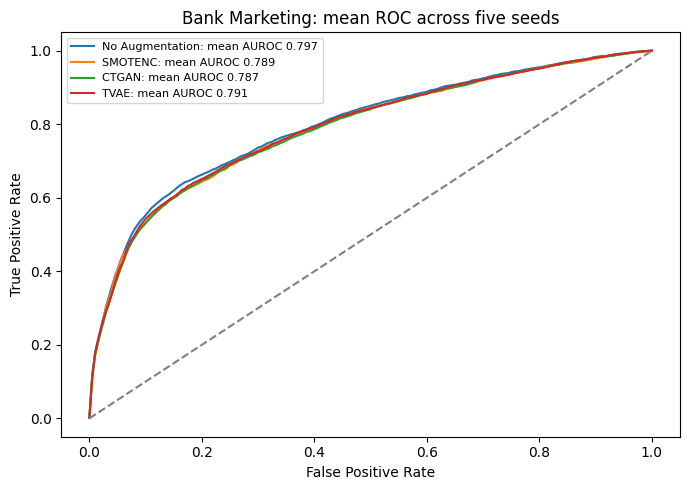

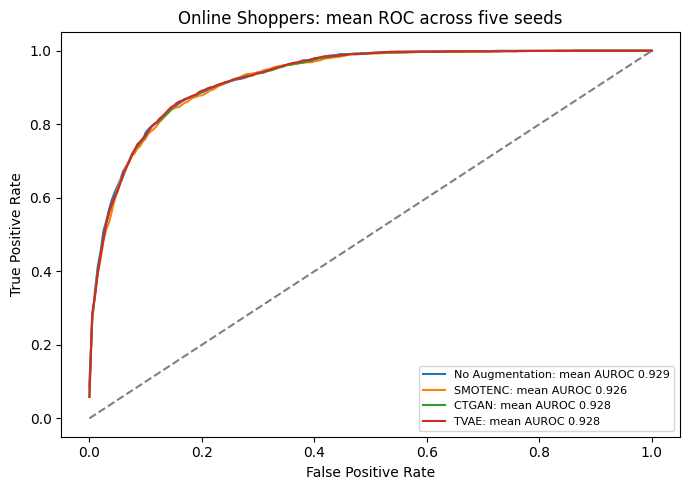

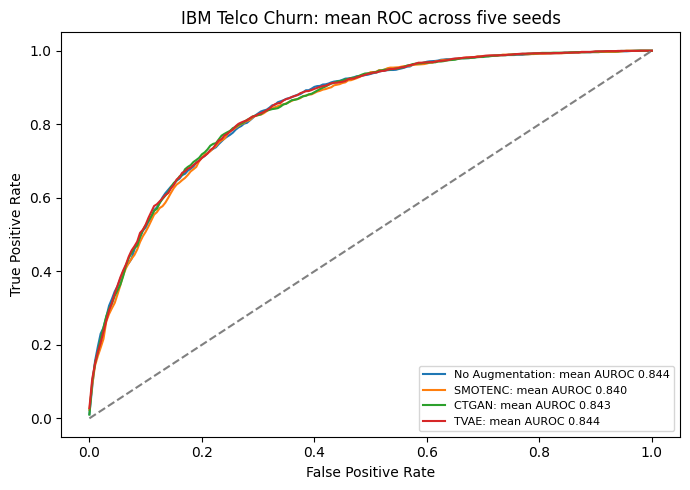

In [8]:
# Each ROC line is the mean of the five held-out ROC curves (interpolated on common FPR grid).
# Curves reflect different test splits, so the mean ROC is descriptive; AUROC summary is in the table.
fpr_grid = np.linspace(0, 1, 201)
for dataset in DATASETS:
    plt.figure(figsize=(7, 5))
    for method in ['No Augmentation', 'SMOTENC', 'CTGAN', 'TVAE']:
        matched = [r['curve'] for r in roc_rows if r['Dataset'] == dataset and r['Method'] == method]
        if len(matched) != len(SEEDS):
            raise ValueError('Missing ROC curves')
        mean_tpr = np.mean([np.interp(fpr_grid, fpr, tpr) for fpr, tpr in matched], axis=0)
        mean_auc = performance.loc[(performance.Dataset == dataset) & (performance.Method == method), 'AUROC'].mean()
        plt.plot(fpr_grid, mean_tpr, label=f'{method}: mean AUROC {mean_auc:.3f}')
    plt.plot([0, 1], [0, 1], '--', color='gray')
    plt.title(f'{dataset}: mean ROC across five seeds')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(dataset.lower().replace(' ', '_') + '_mean_roc_5_seeds.png', dpi=160)
    plt.show()


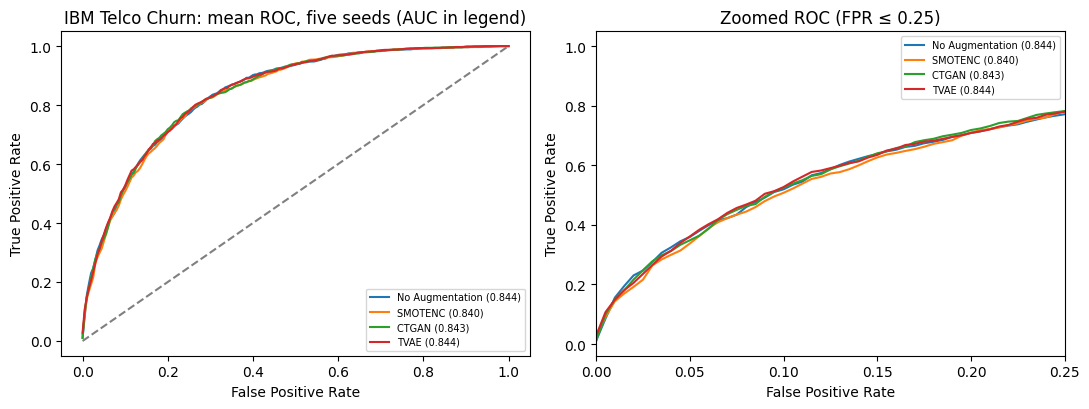

In [17]:
fpr_grid = np.linspace(0, 1, 201)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, zoom in zip(axes, [False, True]):
    for method in ['No Augmentation', 'SMOTENC', 'CTGAN', 'TVAE']:
        m = [r['curve'] for r in roc_rows if r['Dataset']=='IBM Telco Churn' and r['Method']==method]
        tpr = np.mean([np.interp(fpr_grid, f, t) for f, t in m], axis=0)
        auc_m = performance.loc[(performance.Dataset=='IBM Telco Churn')&(performance.Method==method),'AUROC'].mean()
        ax.plot(fpr_grid, tpr, label=f'{method} ({auc_m:.3f})')
    if zoom: ax.set_xlim(0, 0.25); ax.set_title('Zoomed ROC (FPR ≤ 0.25)')
    else: ax.plot([0,1],[0,1],'--',color='gray'); ax.set_title('IBM Telco Churn: mean ROC, five seeds (AUC in legend)')
    ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate'); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig('telco_roc_two_panel.png', dpi=200); plt.show()

---
# Proposed AQHDA — Progressive selection + Optuna (VALIDATION ONLY)

**Independent experimental extension.** The 5-seed baseline cells above are unchanged. For each seed and dataset, regenerate candidate minority rows using **SMOTENC, CTGAN and TVAE fitted on TRAIN only** and combine them into a pool. This takes additional runtime because the earlier baseline did not save the generated rows by seed.

Instead of forcing all quality constraints at once, test stages individually:

- **B — Valid random:** remove clearly unusable rows, then randomly select from the same pool (equal-size control).
- **C — Realism:** favor samples close to genuine TRAIN minority examples.
- **D — Realism + informativeness:** balance realism with boundary uncertainty. Being near the decision boundary is a *hypothesis* for informativeness, not a guarantee.
- **E — Progressive:** add class-consistency support and diversity to the softer weighted scoring; avoid overly strict hard filtering.
- **E + Optuna:** optimize soft selection weights and the mix of candidate properties using **validation AP (AUPRC)**, subject to a majority-class F1 guard. Do not use Test here.

Report the mean ± SD across five splits; compare against **No Augmentation, individual generators and random pool selection with an identical synthetic-row budget**. Do not claim an improvement unless it holds up on a new locked test and across seeds. All reported numbers in this section are **validation only** and must not be mixed with the preceding test tables. Statistical quality metrics remain separate from predictive utility.

## 1. Setup and candidate-pool checks

In [9]:
%pip -q install optuna

In [10]:
import os
import random
import warnings
import optuna
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import average_precision_score, f1_score, precision_score, recall_score, roc_auc_score

# Change only these two settings if you need a quicker trial run.
AQHDA_TRIALS = 12           # Optuna trials per dataset and seed; increase after a pilot
AQHDA_SEEDS = [42, 123, 2024, 2025, 2026]
AQHDA_MAJORITY_F1_GUARD = 0.02  # Max allowed loss in MAJORITY F1 at fixed 0.50 threshold
AQHDA_K_NEIGHBORS = 5
AQHDA_CLUSTERS = 10

optuna.logging.set_verbosity(optuna.logging.WARNING)

def aqhda_clean_pool(raw_pool, X_train, cats, nums):
    """Remove unusable rows, no artificial hard cutoff on realism/informativeness."""
    p = raw_pool[X_train.columns].copy().reset_index(drop=True)
    for c in cats:
        p[c] = p[c].astype(str)
    for c in nums:
        p[c] = pd.to_numeric(p[c], errors='coerce')
    valid = np.ones(len(p), dtype=bool)
    for c in nums:
        valid &= np.isfinite(p[c].to_numpy(dtype=float))
    for c in cats:
        valid &= p[c].isin(X_train[c].astype(str).unique()).to_numpy()
    valid_pool = p.loc[valid].copy().reset_index(drop=True)
    # Remove exact duplicates (but NOT merely similar rows).
    valid_pool = valid_pool.drop_duplicates().reset_index(drop=True)
    real_keys = pd.MultiIndex.from_frame(X_train[X_train.columns].copy().reset_index(drop=True))
    pool_keys = pd.MultiIndex.from_frame(valid_pool)
    valid_pool = valid_pool.loc[~pool_keys.isin(real_keys)].reset_index(drop=True)
    return valid_pool, {'candidate_count':len(raw_pool), 'remaining':len(valid_pool),
                        'invalid_removed':int((~valid).sum()),
                        'duplicates_or_real_copies_removed':int(valid.sum())-len(valid_pool)}


def aqhda_get_features(X_train, pool, cats, nums):
    """Mixed-type distance, with preprocessing learned from TRAIN only."""
    transform = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), cats),
        ('num', StandardScaler(), nums)], sparse_threshold=0.3)
    # Scale by real TRAIN data, never by validation or test.
    transform.fit(X_train)
    return transform.transform(X_train), transform.transform(pool)


def aqhda_minmax(values):
    a = np.asarray(values, dtype=float)
    if len(a) == 0:
        return a
    a = np.nan_to_num(a, nan=np.nanmedian(a[np.isfinite(a)]) if np.isfinite(a).any() else 0)
    low, high = np.percentile(a, [5, 95])
    return np.clip((a-low)/max(high-low, 1e-8), 0, 1)


## 2. Score realism, informativeness, minority-label support and diversity

In [11]:
def aqhda_candidate_scores(X_train, y_train, pool, cats, nums, reference_model, seed):
    """All candidate scores use TRAIN and its learned model; no validation labels."""
    minority = X_train.loc[y_train == 1].reset_index(drop=True)
    # Both sets are transformed with the same TRAIN-fitted encoder/scaler.
    transformer = ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='ignore'), cats),
        ('num', StandardScaler(), nums)], sparse_threshold=0.3)
    transformer.fit(X_train)
    real_encoded = transformer.transform(minority)
    pool_encoded = transformer.transform(pool)

    knn = NearestNeighbors(n_neighbors=min(AQHDA_K_NEIGHBORS, len(minority)), n_jobs=2)
    knn.fit(real_encoded)
    d = knn.kneighbors(pool_encoded, return_distance=True)[0]
    nearest_distance = d[:, 0]
    mean_distance = d.mean(axis=1)

    # Near REAL minority observations = realism/density support. Not a hard gate.
    realism = 1.0 - aqhda_minmax(mean_distance)
    # Novelty can be good, but extreme distances may be invalid/outliers;
    # assign highest soft novelty to moderate distances instead of extremes.
    novelty = aqhda_minmax(nearest_distance)
    diversity = 1.0 - np.abs(novelty - 0.55) / 0.55
    diversity = np.clip(diversity, 0, 1)

    minority_prob = np.clip(reference_model.predict_proba(pool)[:, 1], 1e-6, 1-1e-6)
    label_support = minority_prob  # Proxy, NOT verification of true synthetic labels.
    informativeness = 4 * minority_prob * (1 - minority_prob)  # Boundary uncertainty proxy.

    # Clusters support a varied sample selection without rejecting useful candidates.
    count = min(AQHDA_CLUSTERS, max(1, len(pool) // 40))
    if count >= 2:
        km = MiniBatchKMeans(n_clusters=count, random_state=seed,
                             batch_size=min(1024, len(pool)), n_init=3)
        cluster = km.fit_predict(pool_encoded)
    else:
        cluster = np.zeros(len(pool), dtype=int)
    return pd.DataFrame({'realism':realism, 'informativeness':informativeness,
                         'label_support':label_support, 'diversity':diversity,
                         'cluster':cluster})


def aqhda_select(scores, budget, weights, seed, cluster_balance=False):
    """Soft weighted ranking; optional cluster-balanced allocation."""
    budget = min(int(budget), len(scores))
    if budget <= 0: return np.array([], dtype=int)
    keys = ['realism', 'informativeness', 'label_support', 'diversity']
    w = np.maximum(np.array([weights.get(k, 0) for k in keys], dtype=float), 0)
    w = w / max(w.sum(), 1e-8)
    value = sum(w[i] * scores[keys[i]].to_numpy() for i in range(len(keys)))
    rng = np.random.default_rng(seed)
    value = value + rng.uniform(0, 1e-9, size=len(value))  # Stable tie-break
    order = np.argsort(-value)
    if not cluster_balance:
        return order[:budget]
    # Round-robin over clusters: encourage coverage without an extra hard filter.
    clusters = scores['cluster'].to_numpy()
    groups = {k:list(order[clusters[order] == k]) for k in np.unique(clusters)}
    selection = []
    while len(selection) < budget:
        progress = False
        for k in sorted(groups, key=lambda z: -(len(groups[z]) > 0)):
            if groups[k]:
                selection.append(groups[k].pop(0))
                progress = True
                if len(selection) == budget: break
        if not progress: break
    return np.array(selection, dtype=int)


def aqhda_train_val(X_train, y_train, pool_selected, X_val, y_val, cats, nums, seed):
    """Train with selected rows only; assess on unchanged REAL validation."""
    X_fit = pd.concat([X_train, pool_selected], ignore_index=True)
    y_fit = pd.concat([y_train.reset_index(drop=True),
                       pd.Series(np.ones(len(pool_selected), dtype=int))], ignore_index=True)
    # Existing factory uses global SEED; set by caller at start of each split.
    model = make_classifier(cats, nums)
    model.fit(X_fit, y_fit)
    p = model.predict_proba(X_val)[:, 1]
    pred_half = (p >= 0.5).astype(int)
    maj_f1_half = f1_score(y_val, pred_half, pos_label=0, zero_division=0)
    # Threshold selected ON validation for descriptive secondary metrics only.
    thresholds = np.arange(0.10, 0.91, 0.05)
    t = max(thresholds, key=lambda x: f1_score(y_val, p >= x, pos_label=1, zero_division=0))
    pred = (p >= t).astype(int)
    return {'AP':float(average_precision_score(y_val, p)),
            'AUROC':float(roc_auc_score(y_val,p)),
            'F1_minority_1':float(f1_score(y_val,pred,pos_label=1,zero_division=0)),
            'F1_majority_0':float(f1_score(y_val,pred,pos_label=0,zero_division=0)),
            'Precision_minority_1':float(precision_score(y_val,pred,pos_label=1,zero_division=0)),
            'Recall_minority_1':float(recall_score(y_val,pred,pos_label=1,zero_division=0)),
            'Precision_majority_0':float(precision_score(y_val,pred,pos_label=0,zero_division=0)),
            'Recall_majority_0':float(recall_score(y_val,pred,pos_label=0,zero_division=0)),
            'majority_F1_at_0.50':float(maj_f1_half),
            'threshold_from_validation':round(float(t),2)}


## 3. Run progressive B/C/D/E + Optuna for all five seeds (TEST UNUSED)

In [12]:
# This cell regenerates synthetic candidate pools. Full 5-seed runs may take time.
AQHDA_OPTUNA_TRIALS = []
AQHDA_ROWS = []
AQHDA_POOL_AUDIT = []
AQHDA_SELECTED_QUALITY = []
AQHDA_WEIGHTS = []

for seed in AQHDA_SEEDS:
    SEED = seed  # Required by original split and XGBoost functions.
    np.random.seed(seed)
    random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except ImportError:
        pass
    for name, dataset_id in DATASETS.items():
        print(f'\nAQHDA validation — {name}, seed {seed}')
        X, y, cats, nums = load_dataset(name, dataset_id)
        X_train, X_val, X_test, y_train, y_val, y_test = split_and_fill(X,y,cats,nums)
        # X_test/y_test are returned by the original splitter but NEVER read below.
        counts = y_train.value_counts()
        budget = min(int(counts[0]-counts[1]), int(counts[1]))
        if budget <= 0: raise ValueError('Minority size / budget must be positive')

        reference_model = make_classifier(cats,nums)
        reference_model.fit(X_train,y_train)
        base_metrics = aqhda_train_val(X_train,y_train,X_train.iloc[:0],X_val,y_val,cats,nums,seed)
        guard = base_metrics['majority_F1_at_0.50'] - AQHDA_MAJORITY_F1_GUARD
        AQHDA_ROWS.append({'Seed':seed,'Dataset':name,'Method':'No Augmentation',**base_metrics})

        all_candidates = []
        for generator in ['SMOTENC','CTGAN','TVAE']:
            print('  Generating',generator)
            synthetic = generate_samples(generator,X_train,y_train,cats,budget)
            # Fair generator benchmark on the SAME validation split.
            gen_metrics = aqhda_train_val(X_train,y_train,synthetic,X_val,y_val,cats,nums,seed)
            AQHDA_ROWS.append({'Seed':seed,'Dataset':name,'Method':generator,**gen_metrics})
            all_candidates.append(synthetic)
        raw_pool = pd.concat(all_candidates,ignore_index=True)
        pool, audit = aqhda_clean_pool(raw_pool,X_train,cats,nums)
        AQHDA_POOL_AUDIT.append({'Seed':seed,'Dataset':name,**audit})
        if len(pool) < budget:
            print('  Warning: valid pool smaller than desired budget; using',len(pool))
        actual_budget = min(budget,len(pool))
        if actual_budget == 0:
            raise ValueError(f'{name} seed {seed}: empty pool after basic validity checks')
        scores = aqhda_candidate_scores(X_train,y_train,pool,cats,nums,reference_model,seed)

        # B: valid random, C: realism, D: realism + informativeness,
        # E: all soft factors with cluster-based coverage. NO simultaneous hard thresholds.
        rng = np.random.default_rng(seed)
        selections = {
            'B: Valid Random': rng.choice(len(pool),size=actual_budget,replace=False),
            'C: Realism': aqhda_select(scores,actual_budget,{'realism':1},seed),
            'D: Realism + Information': aqhda_select(scores,actual_budget,
                                               {'realism':0.5,'informativeness':0.5},seed),
            'E: Progressive': aqhda_select(scores,actual_budget,
                  {'realism':0.35,'informativeness':0.30,
                   'label_support':0.20,'diversity':0.15},seed,cluster_balance=True)
        }
        for method, indices in selections.items():
            metrics = aqhda_train_val(X_train,y_train,pool.iloc[indices],X_val,y_val,cats,nums,seed)
            AQHDA_ROWS.append({'Seed':seed,'Dataset':name,'Method':method,**metrics})
            print(f'  {method:27s} val AP={metrics["AP"]:.4f}')

        # Optuna tunes just the E-selection weights; it never observes TEST.
        def objective(trial):
            weights = {k:trial.suggest_float('w_'+k,0.05,1.0)
                       for k in ['realism','informativeness','label_support','diversity']}
            idx = aqhda_select(scores,actual_budget,weights,seed,cluster_balance=True)
            metrics = aqhda_train_val(X_train,y_train,pool.iloc[idx],X_val,y_val,cats,nums,seed)
            allowed = metrics['majority_F1_at_0.50'] >= guard
            trial.set_user_attr('AP',metrics['AP'])
            trial.set_user_attr('guard_pass',bool(allowed))
            AQHDA_OPTUNA_TRIALS.append({'Seed':seed,'Dataset':name,'Trial':trial.number,
                                          'AP':metrics['AP'],'guard_pass':bool(allowed),
                                          **weights})
            # Prefer allowed solutions; invalid trials retain AP for diagnostics.
            return metrics['AP'] if allowed else -1.0

        study = optuna.create_study(direction='maximize',
                  sampler=optuna.samplers.TPESampler(seed=seed))
        study.optimize(objective,n_trials=AQHDA_TRIALS,show_progress_bar=False)
        valid_trials = [t for t in study.trials if t.user_attrs.get('guard_pass',False)]
        if valid_trials:
            best = max(valid_trials,key=lambda t:t.user_attrs['AP'])
            best_weights = {k:best.params['w_'+k]
                            for k in ['realism','informativeness','label_support','diversity']}
            idx = aqhda_select(scores,actual_budget,best_weights,seed,cluster_balance=True)
            chosen = pool.iloc[idx].copy()
            optimized = aqhda_train_val(X_train,y_train,chosen,X_val,y_val,cats,nums,seed)
            # If all selections do worse than real-only, do NOT assert improvement.
            AQHDA_ROWS.append({'Seed':seed,'Dataset':name,'Method':'E + Optuna',**optimized})
            AQHDA_WEIGHTS.append({'Seed':seed,'Dataset':name,'best_trial':best.number,
                                  'selected_val_AP':optimized['AP'], 'noaug_val_AP':base_metrics['AP'],
                                  **best_weights})
            # Diagnostic statistical quality is separate from validation selection objective.
            aq_quality = quality_scores(X_train.loc[y_train==1],chosen,cats,nums)
            AQHDA_SELECTED_QUALITY.append({'Seed':seed,'Dataset':name,**aq_quality})
            chosen.assign(label=1).to_csv(
              f'aqhda_selected_{name.lower().replace(" ","_")}_seed{seed}.csv',index=False)
            print(f'  E + Optuna                  val AP={optimized["AP"]:.4f},'
                  f' No Aug={base_metrics["AP"]:.4f}')
        else:
            # A failed guard must NOT be disguised as a successful Optuna result.
            AQHDA_WEIGHTS.append({'Seed':seed,'Dataset':name,'best_trial':np.nan,
                                  'selected_val_AP':np.nan,'noaug_val_AP':base_metrics['AP'],
                                  'status':'No trial passed majority F1 guard'})
            print('  No Optuna trial passed the majority-class F1 safeguard.')

# Export only VALIDATION results. Never call evaluate_classifier() here (it reads TEST).
aqhda_validation = pd.DataFrame(AQHDA_ROWS)
aqhda_trials = pd.DataFrame(AQHDA_OPTUNA_TRIALS)
aqhda_audit = pd.DataFrame(AQHDA_POOL_AUDIT)
aqhda_weights = pd.DataFrame(AQHDA_WEIGHTS)
aqhda_quality = pd.DataFrame(AQHDA_SELECTED_QUALITY)
for filename,frame in [('aqhda_progressive_validation_per_seed.csv',aqhda_validation),
                       ('aqhda_progressive_optuna_trials.csv',aqhda_trials),
                       ('aqhda_progressive_pool_audit.csv',aqhda_audit),
                       ('aqhda_progressive_best_weights.csv',aqhda_weights),
                       ('aqhda_progressive_selected_quality.csv',aqhda_quality)]:
    frame.to_csv(filename,index=False)

summary_cols = ['AP','AUROC','F1_minority_1','F1_majority_0','Precision_minority_1',
                'Recall_minority_1','Precision_majority_0','Recall_majority_0']
aqhda_summary = aqhda_validation.groupby(['Dataset','Method'])[summary_cols].agg(['mean','std'])
aqhda_summary.to_csv('aqhda_progressive_validation_mean_std.csv')
print('\nVALIDATION — 5-seed mean ± SD; Test not used for AQHDA optimization')
display(aqhda_summary.round(4))
print('Pool cleaning summary:')
display(aqhda_audit)
print('Optimized weight summary:')
display(aqhda_weights)



AQHDA validation — Bank Marketing, seed 42
  Generating SMOTENC
  Generating CTGAN
  Generating TVAE
  B: Valid Random             val AP=0.4299
  C: Realism                  val AP=0.4231
  D: Realism + Information    val AP=0.4296
  E: Progressive              val AP=0.4336
  E + Optuna                  val AP=0.4343, No Aug=0.4381

AQHDA validation — Online Shoppers, seed 42


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

  Generating SMOTENC
  Generating CTGAN
  Generating TVAE
  B: Valid Random             val AP=0.7427
  C: Realism                  val AP=0.7470
  D: Realism + Information    val AP=0.7440
  E: Progressive              val AP=0.7357
  E + Optuna                  val AP=0.7425, No Aug=0.7475

AQHDA validation — IBM Telco Churn, seed 42
Telco source rows: 7043 | blank TotalCharges (imputed with train median): 11


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

  Generating SMOTENC
  Generating CTGAN
  Generating TVAE
  B: Valid Random             val AP=0.6662
  C: Realism                  val AP=0.6657
  D: Realism + Information    val AP=0.6614
  E: Progressive              val AP=0.6598
  E + Optuna                  val AP=0.6716, No Aug=0.6777

AQHDA validation — Bank Marketing, seed 123
  Generating SMOTENC
  Generating CTGAN
  Generating TVAE
  B: Valid Random             val AP=0.4378
  C: Realism                  val AP=0.4445
  D: Realism + Information    val AP=0.4449
  E: Progressive              val AP=0.4451
  E + Optuna                  val AP=0.4471, No Aug=0.4585

AQHDA validation — Online Shoppers, seed 123


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

... (16 outputs left out)

Pool cleaning summary:


,Seed,Dataset,candidate_count,remaining,invalid_removed,duplicates_or_real_copies_removed
0,42,Bank Marketing,9519,9518,0,1
1,42,Online Shoppers,3435,3435,0,0
2,42,IBM Telco Churn,3363,3358,0,5
3,123,Bank Marketing,9519,9519,0,0
4,123,Online Shoppers,3435,3435,0,0
5,123,IBM Telco Churn,3363,3357,0,6
6,2024,Bank Marketing,9519,9519,0,0
7,2024,Online Shoppers,3435,3435,0,0
8,2024,IBM Telco Churn,3363,3357,0,6
9,2025,Bank Marketing,9519,9519,0,0


Optimized weight summary:


,Seed,Dataset,best_trial,selected_val_AP,noaug_val_AP,realism,informativeness,label_support,diversity
0,42,Bank Marketing,0,0.434273,0.438148,0.405813,0.953179,0.745394,0.618726
1,42,Online Shoppers,2,0.742494,0.747540,0.621059,0.722669,0.069555,0.971414
2,42,IBM Telco Churn,11,0.671619,0.677723,0.552468,0.103677,0.850136,0.568703
3,123,Bank Marketing,10,0.447060,0.458527,0.849844,0.126814,0.403986,0.149865
4,123,Online Shoppers,1,0.740563,0.738232,0.733496,0.451951,0.981726,0.700588
5,123,IBM Telco Churn,11,0.673352,0.677233,0.449502,0.859497,0.082988,0.716593
6,2024,Bank Marketing,0,0.444312,0.453531,0.608614,0.714153,0.228744,0.091618
7,2024,Online Shoppers,10,0.760195,0.761353,0.141852,0.094470,0.380829,0.106708
8,2024,IBM Telco Churn,8,0.646962,0.645686,0.277037,0.465836,0.889362,0.324817
9,2025,Bank Marketing,1,0.435239,0.448194,0.418824,0.294717,0.674499,0.517986


In [13]:

# ============================================================
# OLD AQHDA: Target Consistency + Density + Diversity
# Five seeds, three datasets, validation only
# Run AFTER the Progressive AQHDA cell (reuses its helper functions)
# ============================================================

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import average_precision_score
import optuna
import numpy as np
import pandas as pd

OLD_AQHDA_TRIALS = 15
old_results = []
old_weights = []


def old_aqhda_scores(X_train, y_train, pool, cats, nums, seed):
    """Calculate the original three scores using TRAINING only."""

    # 1. TARGET CONSISTENCY
    reference = make_classifier(cats, nums)
    reference.fit(X_train, y_train)
    target = reference.predict_proba(pool)[:, 1]

    # Encode categories and scale numerical variables
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore"), cats),
        ("num", StandardScaler(), nums)
    ])
    prep.fit(X_train)

    minority = X_train.loc[y_train == 1]
    real_points = prep.transform(minority)
    pool_points = prep.transform(pool)

    # 2. DENSITY: proximity to real minority observations
    knn = NearestNeighbors(n_neighbors=min(6, len(minority)))
    knn.fit(real_points)
    distances, _ = knn.kneighbors(pool_points)

    mean_distance = distances.mean(axis=1)
    scale = max(float(np.median(mean_distance)), 1e-9)
    density = np.exp(-mean_distance / scale)

    # 3. DIVERSITY: novelty relative to real minority examples
    nearest = distances[:, 0]
    low, high = np.quantile(nearest, [0.05, 0.95])
    diversity = np.clip(
        (nearest - low) / max(high - low, 1e-9), 0, 1
    )

    # Cluster coverage: avoid selecting from just one region
    n_clusters = min(12, max(2, len(pool) // 200))
    n_clusters = min(n_clusters, len(pool))

    km = MiniBatchKMeans(
        n_clusters=n_clusters,
        random_state=seed,
        batch_size=min(512, len(pool)),
        n_init=3
    )
    clusters = km.fit_predict(pool_points)

    return target, density, diversity, clusters


def old_aqhda_select(pool, score, clusters, budget):
    """Round-robin selection from clusters, ranked by quality."""

    groups = []
    for cluster in np.unique(clusters):
        ids = np.where(clusters == cluster)[0]
        groups.append(list(ids[np.argsort(-score[ids])]))

    selected = []
    while len(selected) < budget:
        progress = False
        for group in groups:
            if group and len(selected) < budget:
                selected.append(group.pop(0))
                progress = True
        if not progress:
            break

    return pool.iloc[selected].reset_index(drop=True)


import random
for seed in AQHDA_SEEDS:
    SEED = seed
    np.random.seed(seed)
    random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
    except ImportError:
        pass

    for name, dataset_id in DATASETS.items():

        print(f"\nOld AQHDA: {name}, seed {seed}")

        X, y, cats, nums = load_dataset(name, dataset_id)

        X_train, X_val, X_test, y_train, y_val, y_test = (
            split_and_fill(X, y, cats, nums)
        )
        # Test data are never used in this experiment.

        counts = y_train.value_counts()
        budget = min(
            int(counts[0] - counts[1]),
            int(counts[1])
        )

        # Generate the original candidate pool
        parts = []
        for method in ["SMOTENC", "CTGAN", "TVAE"]:
            synthetic = generate_samples(
                method, X_train, y_train, cats, budget
            )
            parts.append(synthetic)

        raw_pool = pd.concat(parts, ignore_index=True)

        # Only basic validity checks
        pool, audit = aqhda_clean_pool(
            raw_pool, X_train, cats, nums
        )
        actual_budget = min(budget, len(pool))

        if actual_budget == 0:
            raise ValueError("No valid synthetic candidates")

        target, density, diversity, clusters = old_aqhda_scores(
            X_train, y_train, pool, cats, nums, seed
        )

        # Real-only model: comparison and majority-class guard
        baseline = aqhda_train_val(
            X_train, y_train, X_train.iloc[:0],
            X_val, y_val, cats, nums, seed
        )

        guard = baseline["majority_F1_at_0.50"] - AQHDA_MAJORITY_F1_GUARD

        def objective(trial):
            weights = np.array([
                trial.suggest_float("target", 0.01, 1.0),
                trial.suggest_float("density", 0.01, 1.0),
                trial.suggest_float("diversity", 0.01, 1.0)
            ])
            weights /= weights.sum()

            score = (
                weights[0] * target
                + weights[1] * density
                + weights[2] * diversity
            )

            selected = old_aqhda_select(
                pool, score, clusters, actual_budget
            )

            metrics = aqhda_train_val(
                X_train, y_train, selected,
                X_val, y_val, cats, nums, seed
            )

            passed = metrics["majority_F1_at_0.50"] >= guard
            trial.set_user_attr("guard_pass", bool(passed))

            return metrics["AP"] if passed else -1.0

        study = optuna.create_study(
            direction="maximize",
            sampler=optuna.samplers.TPESampler(seed=seed)
        )
        study.optimize(
            objective,
            n_trials=OLD_AQHDA_TRIALS,
            show_progress_bar=False
        )

        valid_trials = [
            t for t in study.trials
            if t.user_attrs.get("guard_pass", False)
        ]

        if valid_trials:
            best_trial = max(valid_trials, key=lambda t: t.value)

            weights = np.array([
                best_trial.params["target"],
                best_trial.params["density"],
                best_trial.params["diversity"]
            ])
            weights /= weights.sum()

            combined = (
                weights[0] * target
                + weights[1] * density
                + weights[2] * diversity
            )

            selected = old_aqhda_select(
                pool, combined, clusters, actual_budget
            )

            result = aqhda_train_val(
                X_train, y_train, selected,
                X_val, y_val, cats, nums, seed
            )

            old_weights.append({
                "Dataset": name,
                "Seed": seed,
                "Target_Weight": weights[0],
                "Density_Weight": weights[1],
                "Diversity_Weight": weights[2]
            })

            method_name = "Old AQHDA + Optuna"
        else:
            # No acceptable trial; report baseline rather than
            # inventing an acceptable synthetic selection.
            result = baseline
            method_name = "Old AQHDA: No feasible selection"

        old_results.append({
            "Dataset": name,
            "Seed": seed,
            "Method": method_name,
            "Validation_AP": result["AP"],
            "Validation_AUROC": result["AUROC"],
            "Minority_F1": result["F1_minority_1"],
            "Majority_F1": result["F1_majority_0"],
            "Selected_Rows": actual_budget if valid_trials else 0
        })

        print(method_name, "Validation AP:", round(result["AP"], 4))


# Results by seed
old_aqhda_df = pd.DataFrame(old_results)

print("\nOLD AQHDA - PER SEED")
display(old_aqhda_df)

# Five-seed summary
old_aqhda_summary = (
    old_aqhda_df.groupby(["Dataset", "Method"])
    [["Validation_AP", "Validation_AUROC",
      "Minority_F1", "Majority_F1"]]
    .agg(["mean", "std"])
    .round(4)
)

print("\nOLD AQHDA - FIVE SEED SUMMARY")
display(old_aqhda_summary)

# Direct comparison with Progressive AQHDA
new_aqhda_df = pd.DataFrame(AQHDA_ROWS)

comparison = pd.concat([
    old_aqhda_df[["Dataset", "Seed", "Method", "Validation_AP"]]
    .rename(columns={"Validation_AP": "AP"}),

    new_aqhda_df[["Dataset", "Seed", "Method", "AP"]]
], ignore_index=True)

comparison_summary = (
    comparison.groupby(["Dataset", "Method"])["AP"]
    .agg(["mean", "std"])
    .round(4)
)

print("\nOLD VS NEW AQHDA - VALIDATION AUPRC")
display(comparison_summary)

old_aqhda_df.to_csv("old_aqhda_five_seed_results.csv", index=False)
comparison_summary.to_csv("old_vs_new_aqhda_comparison.csv")



Old AQHDA: Bank Marketing, seed 42
Old AQHDA + Optuna Validation AP: 0.4365

Old AQHDA: Online Shoppers, seed 42


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

Old AQHDA + Optuna Validation AP: 0.7437

Old AQHDA: IBM Telco Churn, seed 42
Telco source rows: 7043 | blank TotalCharges (imputed with train median): 11


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

Old AQHDA + Optuna Validation AP: 0.6655

Old AQHDA: Bank Marketing, seed 123
Old AQHDA + Optuna Validation AP: 0.4455

Old AQHDA: Online Shoppers, seed 123


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

... (16 outputs left out)


OLD AQHDA - FIVE SEED SUMMARY


Validation_AP         Validation_AUROC  \
                                            mean     std             mean   
Dataset         Method                                                      
Bank Marketing  Old AQHDA + Optuna        0.4429  0.0060           0.7901   
IBM Telco Churn Old AQHDA + Optuna        0.6603  0.0101           0.8443   
Online Shoppers Old AQHDA + Optuna        0.7492  0.0087           0.9324   

                                           Minority_F1         Majority_F1  \
                                       std        mean     std        mean   
Dataset         Method                                                       
Bank Marketing  Old AQHDA + Optuna  0.0062      0.4807  0.0076      0.9272   
IBM Telco Churn Old AQHDA + Optuna  0.0034      0.6364  0.0112      0.8299   
Online Shoppers Old AQHDA + Optuna  0.0017      0.6904  0.0091      0.9391   

                                            
                                       std  
Dataset         Method                      
Bank Marketing  Old AQHDA + Optuna  0.0043  
IBM Telco Churn Old AQHDA + Optuna  0.0208  
Online Shoppers Old AQHDA + Optuna  0.0034


OLD VS NEW AQHDA - VALIDATION AUPRC


mean     std
Dataset         Method                                  
Bank Marketing  B: Valid Random           0.4349  0.0035
                C: Realism                0.4347  0.0105
                CTGAN                     0.4238  0.0039
                D: Realism + Information  0.4396  0.0087
                E + Optuna                0.4403  0.0056
                E: Progressive            0.4394  0.0048
                No Augmentation           0.4497  0.0076
                Old AQHDA + Optuna        0.4429  0.0060
                SMOTENC                   0.4400  0.0065
                TVAE                      0.4337  0.0057
IBM Telco Churn B: Valid Random           0.6537  0.0151
                C: Realism                0.6470  0.0199
                CTGAN                     0.6471  0.0176
                D: Realism + Information  0.6477  0.0230
                E + Optuna                0.6582  0.0133
                E: Progressive            0.6484  0.0107
                No Augmentation           0.6598  0.0171
                Old AQHDA + Optuna        0.6603  0.0101
                SMOTENC                   0.6508  0.0128
                TVAE                      0.6534  0.0197
Online Shoppers B: Valid Random           0.7464  0.0115
                C: Realism                0.7471  0.0132
                CTGAN                     0.7476  0.0147
                D: Realism + Information  0.7449  0.0111
                E + Optuna                0.7476  0.0098
                E: Progressive            0.7437  0.0095
                No Augmentation           0.7468  0.0132
                Old AQHDA + Optuna        0.7492  0.0087
                SMOTENC                   0.7392  0.0067
                TVAE                      0.7474  0.0149

## 4. Interpret validation results cautiously

1. **Compare B to C/D/E:** improvements from realism or informativeness on validation AP motivate follow-up research but are not proof.
2. **Compare E + Optuna to E and B:** the weights are tuned on the *same validation split*, so validation scores are optimistic.
3. **Fair budgets:** B/C/D/E use the same number of synthetic rows from the same pool.
4. **Proxies:** boundary uncertainty may favor ambiguous or mislabeled rows; KNN realism does not prove feature dependencies or label correctness.
5. **Final test cell below:** it reuses the frozen validation-selected rows and evaluates them once on the same test splits already used for the baseline tables. These are not fresh splits, so treat results as preliminary; do not retune using test data. Several AQHDA variants (progressive and the earlier version) were compared on validation before choosing E + Optuna.


In [14]:

# ============================================================
# AQHDA: FINAL HELD-OUT TEST EVALUATION
# 3 datasets x 5 seeds; compare with original baselines.
# Run AFTER the progressive Optuna validation cell.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd

for variable in ("aqhda_weights", "performance_rows", "AQHDA_SEEDS", "DATASETS"):
    assert variable in globals(), f"Missing {variable}: run earlier experiment cells first."

results = []

for seed in AQHDA_SEEDS:
    SEED = seed  # The existing split and model functions use global SEED.
    np.random.seed(seed)

    for name, dataset_id in DATASETS.items():
        print(f"\nTEST: {name}, seed {seed}")

        locked = aqhda_weights.loc[
            (aqhda_weights["Seed"] == seed) &
            (aqhda_weights["Dataset"] == name)
        ]
        if len(locked) != 1:
            raise ValueError(f"Missing/duplicate locked selection: {name}, seed {seed}")

        if pd.isna(locked.iloc[0]["best_trial"]):
            print("No feasible Optuna selection; not evaluated.")
            results.append({"Dataset": name, "Seed": seed,
                            "Method": "AQHDA E + Optuna",
                            "Status": "No feasible selection"})
            continue

        X, y, cats, nums = load_dataset(name, dataset_id)
        X_train, X_val, X_test, y_train, y_val, y_test = split_and_fill(
            X, y, cats, nums
        )

        filename = Path(
            f'aqhda_selected_{name.lower().replace(" ", "_")}_seed{seed}.csv'
        )
        if not filename.exists():
            raise FileNotFoundError(f"Missing {filename}: restore saved Optuna selections.")

        selected = pd.read_csv(filename)
        if "label" not in selected.columns:
            raise ValueError(f"Missing label in {filename}")
        if not pd.to_numeric(selected["label"], errors="coerce").eq(1).all():
            raise ValueError(f"Invalid minority labels in {filename}")
        selected = selected.drop(columns="label")
        if set(selected.columns) != set(X_train.columns):
            raise ValueError(f"Feature mismatch in {filename}")
        selected = selected.loc[:, X_train.columns].copy()

        counts = y_train.value_counts()
        budget = min(int(counts[0] - counts[1]), int(counts[1]))
        if not (0 < len(selected) <= budget):
            raise ValueError(f"Unexpected selected row count in {filename}: {len(selected)}")

        # Match the model/preprocessing schema used when the selection was saved.
        for col in cats:
            selected[col] = selected[col].astype(str)
            valid_values = X_train[col].astype(str).unique()
            if not selected[col].isin(valid_values).all():
                raise ValueError(f"Unknown category in {col}: {filename}")

        for col in nums:
            selected[col] = pd.to_numeric(selected[col], errors="coerce")
            if not np.isfinite(selected[col].to_numpy(dtype=float)).all():
                raise ValueError(f"Invalid numerical values in {col}: {filename}")

        X_aug = pd.concat([X_train, selected], ignore_index=True)
        y_aug = pd.concat([
            y_train.reset_index(drop=True),
            pd.Series(np.ones(len(selected), dtype=int))
        ], ignore_index=True)

        # Existing function chooses threshold on VAL, reports on TEST.
        metrics, _, _ = evaluate_classifier(
            X_aug, y_aug, X_val, y_val, X_test, y_test, cats, nums
        )
        results.append({"Dataset": name, "Seed": seed,
                        "Method": "AQHDA E + Optuna", "Status": "Evaluated",
                        "Selected_Rows": len(selected), **metrics})
        print(f"Test AP={metrics['AP']:.4f}, "
              f"minority F1={metrics['F1_minority_1']:.4f}, "
              f"majority F1={metrics['F1_majority_0']:.4f}")

# ============================================================
# Compare with baseline TEST results from the original notebook
# ============================================================

aqhda_test = pd.DataFrame(results)
baseline_test = pd.DataFrame(performance_rows).copy()
baseline_test["Status"] = "Evaluated"

all_test_results = pd.concat([baseline_test, aqhda_test],
                             ignore_index=True, sort=False)
metrics_to_compare = [
    "AP", "AUROC", "Precision_minority_1", "Recall_minority_1",
    "F1_minority_1", "Precision_majority_0", "Recall_majority_0",
    "F1_majority_0"
]

summary = (all_test_results.groupby(["Dataset", "Method"])
           [metrics_to_compare].agg(["mean", "std", "count"]).round(4))
print("\nFINAL TEST COMPARISON — FIVE SEEDS")
display(summary)

successful = aqhda_test.loc[aqhda_test["Status"] == "Evaluated"].copy()
no_aug = baseline_test.loc[baseline_test["Method"] == "No Augmentation"].copy()
paired = successful.merge(no_aug, on=["Dataset", "Seed"],
                          suffixes=("_AQHDA", "_NoAug"),
                          validate="one_to_one")
for metric in metrics_to_compare:
    paired["Delta_" + metric] = (
        paired[metric + "_AQHDA"] - paired[metric + "_NoAug"]
    )
delta_cols = ["Delta_" + metric for metric in metrics_to_compare]
print("\nAQHDA MINUS NO AUGMENTATION (PAIRED TEST SEEDS)")
display(paired[["Dataset", "Seed"] + delta_cols])
print("\nMEAN IMPROVEMENT BY DATASET")
if not paired.empty:
    display(paired.groupby("Dataset")[delta_cols]
            .agg(["mean", "std", "count"]).round(4))
else:
    print("No feasible AQHDA selections to compare.")
print("\nNUMBER OF SUCCESSFUL AQHDA EVALUATIONS")
display(aqhda_test.groupby(["Dataset", "Status"]).size())

all_test_results.to_csv("AQHDA_Final_Test_All_Methods.csv", index=False)
summary.to_csv("AQHDA_Final_Test_Mean_SD.csv")
paired.to_csv("AQHDA_Final_Test_Improvements.csv", index=False)
print("\nDone. TEST results saved. Do not retune using TEST data.")



TEST: Bank Marketing, seed 42
Test AP=0.4670, minority F1=0.4954, majority F1=0.9313

TEST: Online Shoppers, seed 42


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

Test AP=0.7408, minority F1=0.6744, majority F1=0.9306

TEST: IBM Telco Churn, seed 42
Telco source rows: 7043 | blank TotalCharges (imputed with train median): 11


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

Test AP=0.6321, minority F1=0.6091, majority F1=0.8087

TEST: Bank Marketing, seed 123
Test AP=0.4400, minority F1=0.4792, majority F1=0.9282

TEST: Online Shoppers, seed 123


/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  frame[c] = frame[c].fillna("Missing").astype(str)
/tmp/ipykernel_1414/2752566030.py:49: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting

... (19 outputs left out)

Delta_AP               Delta_AUROC                \
                    mean     std count        mean     std count   
Dataset                                                            
Bank Marketing   -0.0088  0.0031     5     -0.0057  0.0018     5   
IBM Telco Churn   0.0046  0.0142     5      0.0003  0.0017     5   
Online Shoppers  -0.0087  0.0093     5     -0.0019  0.0017     5   

                Delta_Precision_minority_1                \
                                      mean     std count   
Dataset                                                    
Bank Marketing                     -0.0131  0.0088     5   
IBM Telco Churn                    -0.0027  0.0118     5   
Online Shoppers                    -0.0105  0.0269     5   

                Delta_Recall_minority_1  ... Delta_F1_minority_1  \
                                   mean  ...               count   
Dataset                                  ...                       
Bank Marketing                   0.0010  ...                   5   
IBM Telco Churn                  0.0160  ...                   5   
Online Shoppers                  0.0031  ...                   5   

                Delta_Precision_majority_0                \
                                      mean     std count   
Dataset                                                    
Bank Marketing                     -0.0002  0.0009     5   
IBM Telco Churn                     0.0051  0.0060     5   
Online Shoppers                     0.0004  0.0057     5   

                Delta_Recall_majority_0               Delta_F1_majority_0  \
                                   mean     std count                mean   
Dataset                                                                     
Bank Marketing                  -0.0041  0.0025     5             -0.0022   
IBM Telco Churn                 -0.0068  0.0150     5             -0.0016   
Online Shoppers                 -0.0037  0.0124     5             -0.0018   

                               
                    std count  
Dataset                        
Bank Marketing   0.0015     5  
IBM Telco Churn  0.0078     5  
Online Shoppers  0.0038     5  

[3 rows x 24 columns]


NUMBER OF SUCCESSFUL AQHDA EVALUATIONS


,,0
Dataset,Status,
Bank Marketing,Evaluated,5
IBM Telco Churn,Evaluated,5
Online Shoppers,Evaluated,5



Done. TEST results saved. Do not retune using TEST data.


In [15]:
print(
    all_test_results[
        (all_test_results["Dataset"] == "IBM Telco Churn") &
        (all_test_results["Method"].isin(["TVAE", "AQHDA E + Optuna"]))
    ].groupby("Method")["AP"].mean().to_string(float_format=lambda x: f"{x:.8f}")
)

Method
AQHDA E + Optuna   0.66098000
TVAE               0.65686000


In [16]:
print(summary.round(5).to_string())

                                      AP                 AUROC               Precision_minority_1               Recall_minority_1               F1_minority_1               Precision_majority_0               Recall_majority_0               F1_majority_0              
                                    mean     std count    mean     std count                 mean     std count              mean     std count          mean     std count                 mean     std count              mean     std count          mean     std count
Dataset         Method                                                                                                                                                                                                                                                    
Bank Marketing  AQHDA E + Optuna  0.4405  0.0179     5  0.7908  0.0075     5               0.4597  0.0159     5            0.4961  0.0167     5        0.4771  0.0140     5               0.9325  0.002

## 6. Limitations and next steps

1. **Compare B to C/D/E:** If adding realism or informativeness improves validation AP, this motivates follow-up research but is not proof.
2. **Compare E + Optuna to E and B:** An improvement may reflect tuning to the *same validation set*. It does not establish test-set generalization.
3. **Fair budgets:** B/C/D/E use the same number of synthetic examples from the same pool. Individual generator baselines also use that original target budget; if invalid candidates are removed and the pool is smaller, the difference is reported.
4. **Important limitations:** A boundary uncertainty score is a proxy for informativeness and may favor ambiguous or mislabeled examples. KNN realism does not prove feature dependencies or label correctness. Review the saved *quality* report separately. Repeated splits may share observations between splits; do not select the final method by looking at previous test outcomes.
5. **Next step:** Freeze the selection approach, then evaluate on a newly locked independent test split or a fresh dataset, across repeated seeds. Until then, label every result in this extension **validation only**.